# Homework 4: Evaluation

Evaluación de modelos de clasificación sobre el dataset 2026 de *lead scoring*.

La variable objetivo es `converted`: indica si el cliente se registró en la
plataforma (`1`) o no (`0`).

Dataset: `course_lead_scoring_2026.csv` (release 2026 fijado en el repo del curso).

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score

## Carga de datos

Descargamos el CSV directamente desde el repositorio del curso.

In [2]:
URL = (
    "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main"
    "/cohorts/2026/data/course_lead_scoring_2026.csv"
)

df = pd.read_csv(URL)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.shape

(5000, 9)

## Data preparation

Primero revisamos si hay valores faltantes en las features.

In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Sí hay valores faltantes. Los rellenamos según el enunciado:

- Features categóricas → `'NA'`
- Features numéricas → `0.0`

In [5]:
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = [
    "annual_income",
    "number_of_courses_viewed",
    "interaction_count",
    "lead_score",
]

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Split del dataset

Dividimos en 60% train / 20% validation / 20% test con las llamadas exactas del
enunciado (`random_state=1`). El target `converted` no forma parte de las
features.

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Question 1: ROC AUC feature importance

Para cada variable numérica usamos su valor como *score* y calculamos el ROC AUC
contra `converted`, usando **solo el conjunto de entrenamiento**.

Si el AUC es menor que `0.5`, invertimos la variable (le ponemos `-` delante),
porque una correlación negativa produce un AUC menor que `0.5` y al negarla se
convierte en positiva.

In [7]:
y_train = df_train["converted"].values
y_val = df_val["converted"].values

auc_scores = {}

for feature in numerical:
    auc = roc_auc_score(y_train, df_train[feature])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])
    auc_scores[feature] = auc
    print(f"{feature:28s} AUC = {auc:.3f}")

best_feature = max(auc_scores, key=auc_scores.get)
print("\nVariable con mayor AUC:", best_feature)

annual_income                AUC = 0.608
number_of_courses_viewed     AUC = 0.723
interaction_count            AUC = 0.765
lead_score                   AUC = 0.788

Variable con mayor AUC: lead_score


**Respuesta Q1: `lead_score`** (AUC ≈ 0.788).

## Question 2: Training the model

Aplicamos one-hot encoding con `DictVectorizer` y entrenamos una regresión
logística con:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

Evaluamos el AUC en el conjunto de validación.

In [8]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient="records")
val_dicts = df_val[categorical + numerical].to_dict(orient="records")
test_dicts = df_test[categorical + numerical].to_dict(orient="records")

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

X_train.shape, X_val.shape, X_test.shape

((3000, 28), (1000, 28), (1000, 28))

In [9]:
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred_proba = model.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred_proba)

print("AUC validation:", round(auc_val, 3))

AUC validation: 0.732


**Respuesta Q2: 0.732** (0.7318 redondeado a 3 decimales).

## Question 3: Precision and Recall

Evaluamos el modelo en todos los umbrales de `0.0` a `1.0` con paso `0.01` y
calculamos precisión y recall para cada uno. Luego graficamos ambas curvas.

Para encontrar el punto de intersección ignoramos los umbrales en los que ambas
métricas son cero y elegimos el umbral con la menor diferencia absoluta entre
precisión y recall.

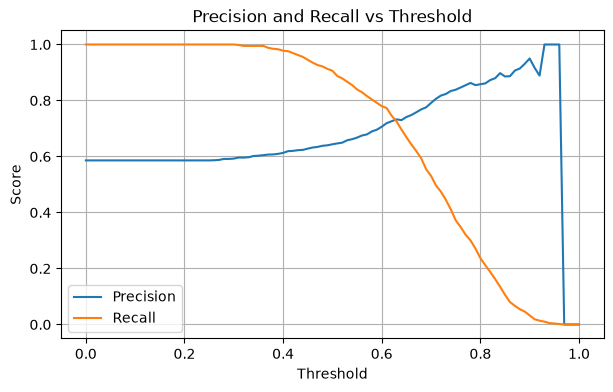

In [10]:
thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    y_pred = (y_pred_proba >= t).astype(int)
    precisions.append(precision_score(y_val, y_pred, zero_division=0))
    recalls.append(recall_score(y_val, y_pred, zero_division=0))

precisions = np.array(precisions)
recalls = np.array(recalls)

plt.figure(figsize=(7, 4))
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold")
plt.grid(True)
plt.legend()
plt.show()

In [11]:
valid = (precisions > 0) | (recalls > 0)
diffs = np.abs(precisions - recalls)
diffs[~valid] = np.inf

best_idx = int(np.argmin(diffs))
best_threshold_q3 = thresholds[best_idx]

print(f"Umbral: {best_threshold_q3:.2f}")
print(f"Precision: {precisions[best_idx]:.3f}")
print(f"Recall: {recalls[best_idx]:.3f}")
print(f"Diferencia absoluta: {diffs[best_idx]:.3f}")

Umbral: 0.63
Precision: 0.733
Recall: 0.725
Diferencia absoluta: 0.008


**Respuesta Q3: 0.63** (precisión ≈ 0.733 y recall ≈ 0.725).

## Question 4: F1 score

El F1 combina precisión y recall:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Calculamos el F1 para todos los umbrales de `0.0` a `1.0` con incremento `0.01`
y buscamos el umbral donde es máximo.

In [12]:
f1_scores = np.array([
    2 * p * r / (p + r) if (p + r) > 0 else 0.0
    for p, r in zip(precisions, recalls)
])

best_f1_idx = int(np.argmax(f1_scores))
best_threshold_q4 = thresholds[best_f1_idx]

print(f"Umbral: {best_threshold_q4:.2f}")
print(f"F1: {f1_scores[best_f1_idx]:.3f}")

Umbral: 0.41
F1: 0.758


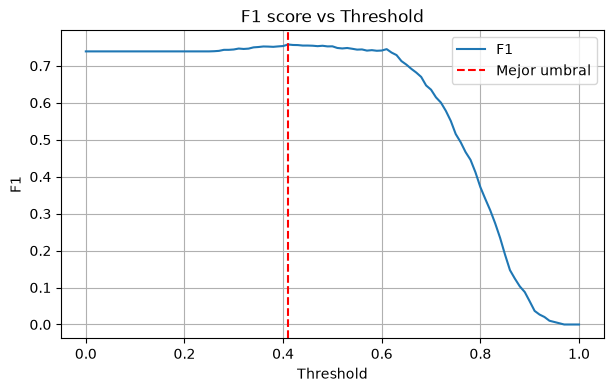

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1_scores, label="F1")
plt.axvline(best_threshold_q4, color="red", linestyle="--", label="Mejor umbral")
plt.xlabel("Threshold")
plt.ylabel("F1")
plt.title("F1 score vs Threshold")
plt.grid(True)
plt.legend()
plt.show()

**Respuesta Q4: 0.41** (F1 ≈ 0.758).

## Question 5: 5-Fold CV

Evaluamos el modelo con `KFold(n_splits=5, shuffle=True, random_state=1)` sobre
`df_full_train`.

En cada fold:

1. Dividimos en train y validation.
2. Entrenamos `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`.
3. Calculamos el AUC en validation.

Finalmente obtenemos la desviación estándar de los 5 scores.

In [14]:
kf = KFold(n_splits=5, shuffle=True, random_state=1)

cv_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(df_full_train), start=1):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    dv_fold = DictVectorizer(sparse=False)
    X_tr = dv_fold.fit_transform(
        df_tr[categorical + numerical].to_dict(orient="records")
    )
    X_va = dv_fold.transform(
        df_va[categorical + numerical].to_dict(orient="records")
    )

    m = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    m.fit(X_tr, df_tr["converted"].values)

    auc = roc_auc_score(
        df_va["converted"].values, m.predict_proba(X_va)[:, 1]
    )
    cv_scores.append(auc)

    print(f"Fold {fold}: AUC = {auc:.4f}")

cv_scores = np.array(cv_scores)
print(f"\nMedia: {cv_scores.mean():.4f}")
print(f"Desviación estándar: {cv_scores.std():.4f} -> {cv_scores.std():.3f}")

Fold 1: AUC = 0.7306
Fold 2: AUC = 0.7296
Fold 3: AUC = 0.7363
Fold 4: AUC = 0.7412


Fold 5: AUC = 0.7209

Media: 0.7317
Desviación estándar: 0.0069 -> 0.007


**Respuesta Q5: 0.007** (desviación estándar de los scores ≈ 0.00685).

## Question 6: Hyperparameter Tuning

Usamos 5-Fold cross-validation para encontrar el mejor valor de `C` entre
`[0.000001, 0.001, 1]`, manteniendo el mismo `KFold` y los mismos parámetros del
modelo.

Para cada `C` calculamos la media y la desviación estándar del ROC AUC,
redondeadas a 3 decimales. Si hay empate, elegimos el menor `std`; si aún hay
empate, el menor `C`.

In [15]:
for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kf.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        dv_c = DictVectorizer(sparse=False)
        X_tr = dv_c.fit_transform(
            df_tr[categorical + numerical].to_dict(orient="records")
        )
        X_va = dv_c.transform(
            df_va[categorical + numerical].to_dict(orient="records")
        )

        m = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        m.fit(X_tr, df_tr["converted"].values)

        auc = roc_auc_score(
            df_va["converted"].values, m.predict_proba(X_va)[:, 1]
        )
        scores.append(auc)

    mean_auc = round(float(np.mean(scores)), 3)
    std_auc = round(float(np.std(scores)), 3)
    print(f"C = {C:<9} mean AUC = {mean_auc}   std = {std_auc}")

C = 1e-06     mean AUC = 0.617   std = 0.019


C = 0.001     mean AUC = 0.749   std = 0.01


C = 1         mean AUC = 0.732   std = 0.007


**Respuesta Q6: `C = 0.001`** (mean AUC ≈ 0.749, std ≈ 0.010).

## Resumen de respuestas

In [16]:
summary = pd.DataFrame(
    [
        ("Q1", "mayor AUC de feature numérica", "lead_score (0.788)"),
        ("Q2", "AUC en validación", 0.732),
        ("Q3", "umbral donde precision = recall", 0.63),
        ("Q4", "umbral con F1 máximo", 0.41),
        ("Q5", "std del AUC en 5-Fold CV", 0.007),
        ("Q6", "mejor C", 0.001),
    ],
    columns=["pregunta", "concepto", "respuesta"],
).set_index("pregunta")

summary

,concepto,respuesta
pregunta,,
Q1,mayor AUC de feature numérica,lead_score (0.788)
Q2,AUC en validación,0.732
Q3,umbral donde precision = recall,0.63
Q4,umbral con F1 máximo,0.41
Q5,std del AUC en 5-Fold CV,0.007
Q6,mejor C,0.001
